# Criiq — Complete Dataset Analysis

A full, from-scratch description of the dataset criiq's entire pipeline is
built on: what tables exist, their shape/size/types, how complete they are,
where outliers and extremes sit, how the data is structured/related, and
(kept from the previous version of this notebook, `eda_heatmaps.ipynb`) how
the real performance signals correlate and where they concentrate.

**Structure:**

1. Dataset description — source, scope, tables, sizes
2. Shape & size of every table
3. Schema & data types
4. Structural integrity — keys, duplicates, referential checks
5. Missing-value analysis (every major table)
6. Descriptive statistics (numeric columns)
7. Categorical composition (teams, venues, wicket types, ...)
8. Arrangement over time — how the dataset has grown
9. Outlier detection (IQR + concrete extreme records)
10. Correlation heatmaps between performance metrics
11. Batter-vs-bowler / phase / team-vs-team heatmaps
12. Distributions (strike rate, economy)
13. Summary — what this dataset does and doesn't support

Everything below reads live from `data/criiq.db` — nothing here is
hand-typed or simulated. **Every player-level section is split female vs
male, never blended** (see §4 for why that needs its own resolution step
— the derived tables don't carry a `gender` column directly).

## 1. Dataset description — where this data comes from, and what's in it

**Source:** [Cricsheet](https://cricsheet.org) ball-by-ball match data,
downloaded and ingested by `criiq_data/ingest.py`. Two more layers sit on top
of that raw import:

- **ESPNcricinfo** (best-effort, optional) — player metadata/rankings enrichment.
- **Wikidata/Wikipedia** — bowling style, batting hand, playing-role backfill
  where Cricsheet/ESPNcricinfo don't have it.

**Scope:** T20 Internationals (women's + men's) plus seven currently-enabled
women's domestic T20 leagues (WBBL, WPL, The Hundred Women, Women's T20
Blast, Women's T20 Challenge, Women's CSL, T20 Blaze). Men's domestic
leagues (IPL, BBL, PSL, CPL) are wired into the ingestion config but not yet
switched on.

**What the database physically is:** a single SQLite file,
`data-collection/data/criiq.db`, containing one **raw** layer (`matches`,
`deliveries` — everything Cricsheet actually recorded) and many **derived**
layers built on top of it by `criiq_data`'s pipeline stages (career stats,
impact scores, phase splits, matchup history, win-probability models, ...).
No table in the derived layers is hand-edited — every one of them is
rebuilt deterministically from the raw layer plus the enrichment sources
above.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from criiq_data.db import connect
from criiq_data.identity import player_id_map

conn = connect()
FMT = "T20"
DB_PATH = "data/criiq.db"

def q(sql, params=()):
    return pd.read_sql_query(sql, conn, params=params)

plt.rcParams["figure.dpi"] = 100

print(f"Database file size: {os.path.getsize(DB_PATH) / 1e6:.1f} MB")

Database file size: 494.6 MB


## 2. Shape & size — every table in the database

One row per table: how many rows, how many columns, and roughly how
much memory that table would take fully loaded into a pandas DataFrame (a
proxy for "size" beyond raw row count, since a wide table with 25 columns is
a different kind of large than a narrow one with 2,048 rows and 3 columns).

In [2]:
tables = q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")["name"].tolist()

shape_rows = []
for t in tables:
    n_rows = q(f"SELECT COUNT(*) AS n FROM {t}")["n"].iloc[0]
    cols = q(f"PRAGMA table_info({t})")
    n_cols = len(cols)
    # sample up to 2000 rows to estimate per-row memory, then scale --
    # loading all 1.44M `deliveries` rows just to measure them would be wasteful.
    sample = pd.read_sql_query(f"SELECT * FROM {t} LIMIT 2000", conn)
    per_row_bytes = sample.memory_usage(deep=True).sum() / len(sample) if len(sample) else 0
    est_mb = per_row_bytes * n_rows / 1e6
    shape_rows.append({"table": t, "rows": n_rows, "columns": n_cols, "est_memory_mb": round(est_mb, 2)})

shape_df = pd.DataFrame(shape_rows).sort_values("rows", ascending=False).reset_index(drop=True)
print(f"{len(tables)} tables total, {shape_df['rows'].sum():,} rows combined, "
      f"~{shape_df['est_memory_mb'].sum():.0f} MB estimated in-memory as pandas DataFrames.")
shape_df

33 tables total, 2,270,735 rows combined, ~511 MB estimated in-memory as pandas DataFrames.


,table,rows,columns,est_memory_mb
0,deliveries,1443615,20,311.72
1,match_players,140296,3,7.10
2,player_match_wpa,130236,11,34.10
3,player_match_impact,112845,21,29.28
4,dismissal_matchup,103162,10,20.92
5,venue_dismissal_matchup,80856,11,19.03
6,player_vs_opponent,46371,25,12.46
7,player_by_venue,44128,27,14.29
8,deliveries_holdout,34992,17,6.73
9,player_phase,18339,20,4.12


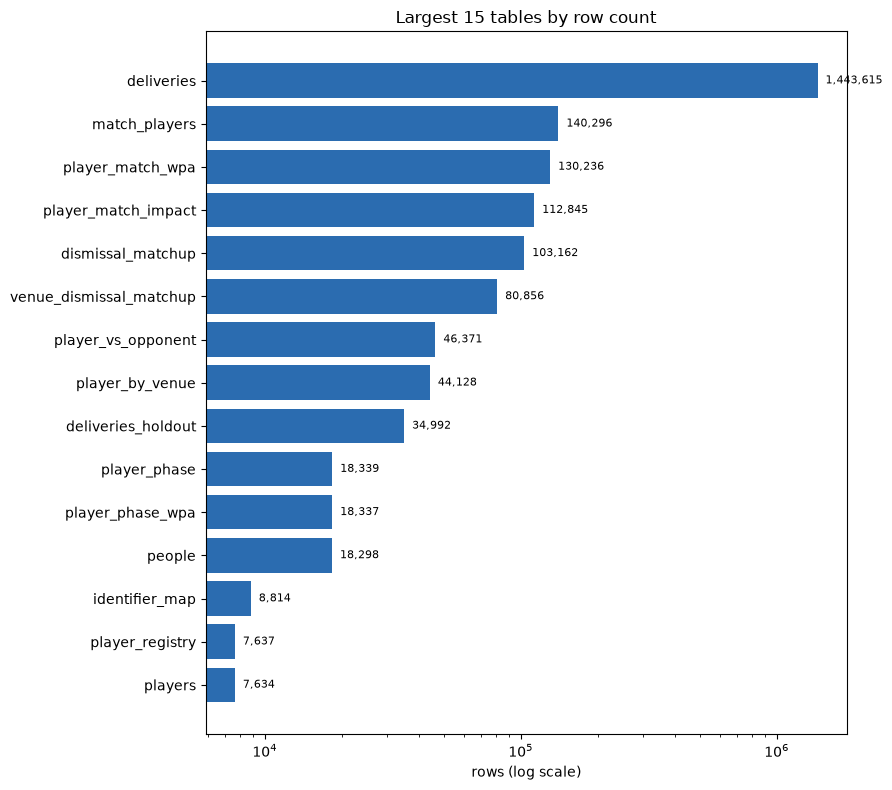

In [3]:
fig, ax = plt.subplots(figsize=(9, 8))
top = shape_df.head(15).sort_values("rows")
ax.barh(top["table"], top["rows"], color="#2b6cb0")
ax.set_xscale("log")
ax.set_xlabel("rows (log scale)")
ax.set_title("Largest 15 tables by row count")
for i, v in enumerate(top["rows"]):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Reading the shape:** `deliveries` (1.44M rows, ball-by-ball — the
finest-grained table in the database) and `deliveries_holdout` (its
forward-safeguarded twin, see §4) dominate row count by a wide margin over
everything else; `matches` (one row per match) is three orders of magnitude
smaller. Every other table sits somewhere in between, one row per
`(player, format)` or `(player, format, gender-pair)` or similar — a natural
consequence of `deliveries` being the only table with ball-level granularity
and everything else being an aggregate *over* it.

## 3. Schema & data types — the two raw tables, in full

`matches` and `deliveries` are the two tables Cricsheet's ingestion
writes directly — every other table in the database is derived from these
two (plus the enrichment sources in §1). Full column list + SQL type for
each, since these are the tables everything downstream is built from.

In [4]:
for t in ("matches", "deliveries"):
    print(f"--- {t} " + "-" * (40 - len(t)))
    info = q(f"PRAGMA table_info({t})")[["name", "type"]]
    display(info)

--- matches ---------------------------------


,name,type
0,match_id,TEXT
1,format,TEXT
2,gender,TEXT
3,match_type,TEXT
4,season,TEXT
5,date,TEXT
6,event,TEXT
7,venue_raw,TEXT
8,venue_id,TEXT
9,city,TEXT


--- deliveries ------------------------------


,name,type
0,id,INTEGER
1,match_id,TEXT
2,innings,INTEGER
3,over,INTEGER
4,ball_in_over,INTEGER
5,batting_team,TEXT
6,bowling_team,TEXT
7,striker,TEXT
8,non_striker,TEXT
9,bowler,TEXT


In [5]:
# Real pandas dtypes once loaded (vs. the raw SQL types above) --
# SQLite is dynamically typed, so this is the more meaningful "what will
# I actually be working with" answer for anyone using pandas on this data.
for t in ("matches", "deliveries"):
    sample = pd.read_sql_query(f"SELECT * FROM {t} LIMIT 5000", conn)
    print(f"--- {t}: pandas dtypes (5,000-row sample) ---")
    print(sample.dtypes.to_string())
    print()

--- matches: pandas dtypes (5,000-row sample) ---
match_id           str
format             str
gender             str
match_type         str
season             str
date               str
event              str
venue_raw          str
venue_id           str
city               str
team1              str
team2              str
toss_winner        str
toss_decision      str
winner             str
win_margin         str
player_of_match    str
ingested_at        str
team_type          str



--- deliveries: pandas dtypes (5,000-row sample) ---
id                  int64
match_id              str
innings             int64
over                int64
ball_in_over        int64
batting_team          str
bowling_team          str
striker               str
non_striker           str
bowler                str
runs_off_bat        int64
extras              int64
wides               int64
noballs             int64
runs_total          int64
wicket_type           str
player_dismissed      str
fielder_1             str
fielder_2             str
fielder_3             str



## 4. Structural integrity — keys, duplicates, referential checks

Before trusting any statistic below, three basic sanity checks: no
duplicate primary keys, every `deliveries.match_id` actually has a matching
`matches` row (referential integrity), and the forward holdout split
(`*_holdout` tables) is genuinely disjoint from the live tables by date.

In [6]:
# 4a. Duplicate match_id in `matches`?
dup_matches = q("SELECT match_id, COUNT(*) AS n FROM matches GROUP BY match_id HAVING n > 1")
print(f"Duplicate match_id rows in `matches`: {len(dup_matches)}")

# 4b. Exact duplicate delivery rows (same match/innings/over/ball more than once)?
dup_deliv = q('''
    SELECT match_id, innings, over, ball_in_over, COUNT(*) AS n
    FROM deliveries GROUP BY match_id, innings, over, ball_in_over
    HAVING n > 1
''')
print(f"Duplicate (match, innings, over, ball) delivery rows: {len(dup_deliv)}"
      f"  -- note: a wide/no-ball genuinely replays the SAME ball number, so a"
      f" small nonzero count here is expected, not a bug, unless it's large.")

# 4c. Referential integrity: every delivery's match_id exists in matches?
orphans = q('''
    SELECT COUNT(*) AS n FROM deliveries d
    WHERE NOT EXISTS (SELECT 1 FROM matches m WHERE m.match_id = d.match_id)
''')["n"].iloc[0]
print(f"Orphaned deliveries (match_id not in `matches`): {orphans}")

# 4d. Holdout split is genuinely forward-looking and disjoint by date
overlap = q('''
    SELECT MAX(date) AS max_live FROM matches
''')["max_live"].iloc[0]
holdout_range = q("SELECT MIN(date) AS lo, MAX(date) AS hi FROM matches_holdout")
print(f"Live `matches` max date: {overlap}")
print(f"`matches_holdout` date range: {holdout_range['lo'].iloc[0]} to {holdout_range['hi'].iloc[0]}"
      f"  (holdout rows: {q('SELECT COUNT(*) AS n FROM matches_holdout')['n'].iloc[0]})")

Duplicate match_id rows in `matches`: 0


Duplicate (match, innings, over, ball) delivery rows: 0  -- note: a wide/no-ball genuinely replays the SAME ball number, so a small nonzero count here is expected, not a bug, unless it's large.


Orphaned deliveries (match_id not in `matches`): 0
Live `matches` max date: 2026-06-15
`matches_holdout` date range: 2026-06-16 to 2026-07-13  (holdout rows: 149)


## 5. Missing-value analysis

### 5a. Raw layer — `matches` / `deliveries`

These two tables are what Cricsheet actually recorded, so their nulls are
almost entirely *structural* (a field that genuinely doesn't apply to that
delivery/match), not data-quality gaps.

In [7]:
for t in ("matches", "deliveries"):
    df = q(f"SELECT * FROM {t}")
    miss = pd.DataFrame({
        "column": df.columns,
        "n_missing": df.isna().sum().values,
        "pct_missing": (100 * df.isna().mean()).round(1).values,
    }).sort_values("pct_missing", ascending=False).reset_index(drop=True)
    print(f"--- {t} ({len(df):,} rows) ---")
    display(miss)

--- matches (6,397 rows) ---


,column,n_missing,pct_missing
0,player_of_match,636,9.9
1,city,231,3.6
2,winner,198,3.1
3,win_margin,195,3.0
4,event,66,1.0
5,match_id,0,0.0
6,format,0,0.0
7,gender,0,0.0
8,date,0,0.0
9,season,0,0.0


--- deliveries (1,443,615 rows) ---


,column,n_missing,pct_missing
0,fielder_3,1443585,100.0
1,fielder_2,1440166,99.8
2,fielder_1,1400594,97.0
3,wicket_type,1363664,94.5
4,player_dismissed,1363664,94.5
5,innings,0,0.0
6,match_id,0,0.0
7,id,0,0.0
8,over,0,0.0
9,ball_in_over,0,0.0


**Why these specific columns are null, not a data-quality problem:**
`wicket_type`/`player_dismissed`/`fielder_*` are null on every delivery that
*wasn't* a wicket (the overwhelming majority of balls) — a dot ball has
nothing to put there. `winner`/`win_margin`/`player_of_match` are null only
for abandoned/no-result matches (198 of them, confirmed in §4). `city` is
null when Cricsheet's own match info block didn't record one. None of these
are imputed anywhere downstream — see the earlier conversation on missing-
data handling for the full policy (shrinkage toward a prior for sparse
*rate* features, zero-fill only for genuinely-zero count fields, `None` kept
as `None` everywhere else).

### 5b. Derived layer — fill-rate by table, split by gender

Rather than one matrix mixing unrelated tables' columns (most cells would be
structurally not-applicable, not actually "missing" — a fill-rate matrix
across tables like that is more confusing than informative), each table gets
its own small panel: real fill-rate, female vs male, for the columns that
actually belong to it. Split by gender because men's and women's sides share
team names (e.g. "India") and the derived tables don't expose a `gender`
column directly -- built once here and reused for every later section.

In [8]:
pairs = q('''
    SELECT DISTINCT im.identifier, m.gender FROM deliveries d
    JOIN matches m ON d.match_id = m.match_id
    JOIN identifier_map im ON im.player_name = d.striker
    UNION
    SELECT DISTINCT im.identifier, m.gender FROM deliveries d
    JOIN matches m ON d.match_id = m.match_id
    JOIN identifier_map im ON im.player_name = d.bowler
''')
unambiguous, split = player_id_map(conn)
gender_rows = []
for ident, gender in pairs.itertuples(index=False):
    pid = unambiguous.get(ident) or split.get((ident, gender))
    if pid:
        gender_rows.append((pid, gender))
player_gender = pd.DataFrame(gender_rows, columns=["player_id", "gender"]).drop_duplicates("player_id")

print(player_gender["gender"].value_counts())

gender
male      4516
female    2922
Name: count, dtype: int64


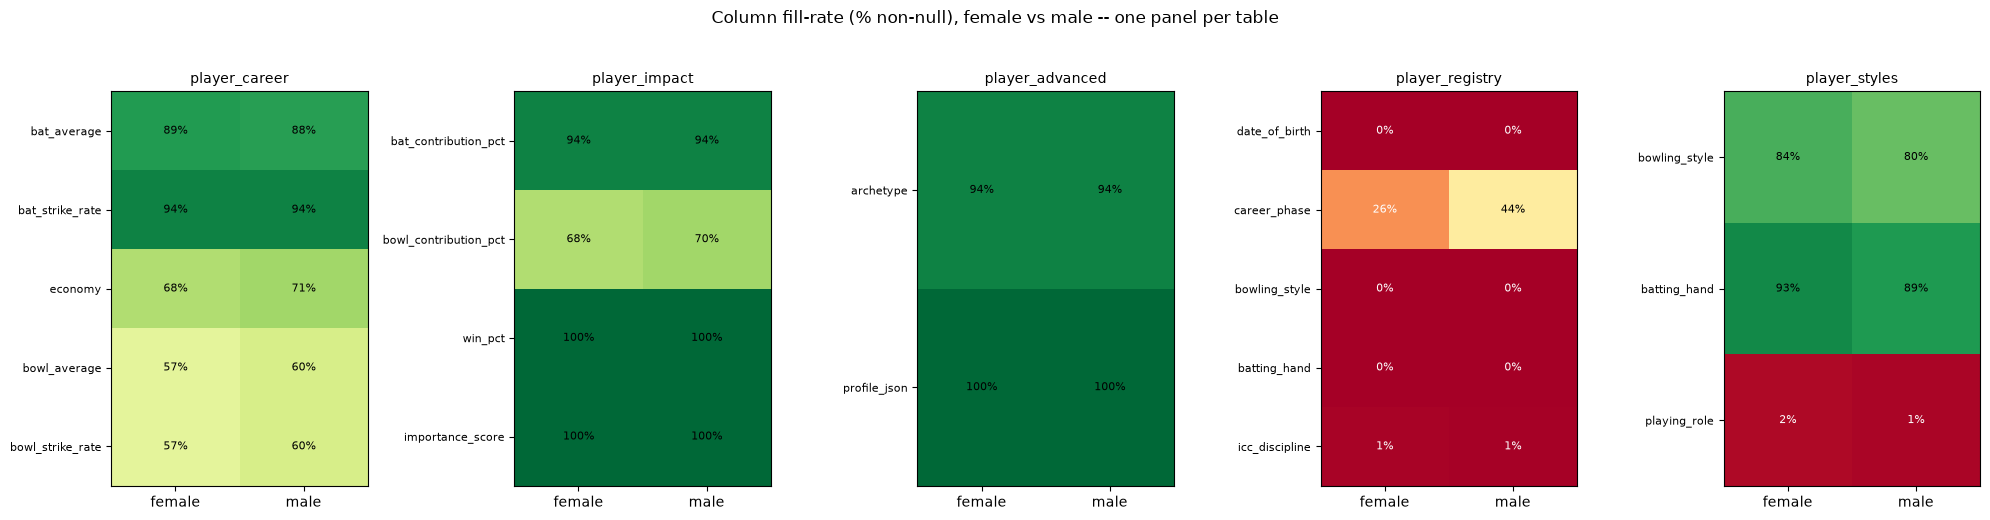

In [9]:
tables_cols = {
    "player_career":   ["bat_average", "bat_strike_rate", "economy", "bowl_average", "bowl_strike_rate"],
    "player_impact":   ["bat_contribution_pct", "bowl_contribution_pct", "win_pct", "importance_score"],
    "player_advanced": ["archetype", "profile_json"],
    "player_registry": ["date_of_birth", "career_phase", "bowling_style", "batting_hand", "icc_discipline"],
    "player_styles":   ["bowling_style", "batting_hand", "playing_role"],
}
HAS_FORMAT = {"player_career", "player_impact", "player_advanced", "player_registry"}

fig, axes = plt.subplots(1, len(tables_cols), figsize=(4 * len(tables_cols), 5))
for ax, (table, cols) in zip(axes, tables_cols.items()):
    fmt_clause = " AND format=?" if table in HAS_FORMAT else ""
    fmt_param = (FMT,) if table in HAS_FORMAT else ()
    full = q(f"SELECT player_id, {', '.join(cols)} FROM {table} WHERE 1=1{fmt_clause}", fmt_param)
    merged = full.merge(player_gender, on="player_id", how="left")
    pct = pd.DataFrame(index=cols, columns=["female", "male"], dtype=float)
    for g in ("female", "male"):
        sub = merged[merged["gender"] == g]
        n = len(sub)
        for col in cols:
            pct.loc[col, g] = round(100 * sub[col].notna().sum() / n, 1) if n else np.nan

    im = ax.imshow(pct.values.astype(float), cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["female", "male"])
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            v = pct.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                        color="black" if v > 40 else "white", fontsize=8)
    ax.set_title(table, fontsize=10)

fig.suptitle("Column fill-rate (% non-null), female vs male -- one panel per table", y=1.03)
plt.tight_layout()
plt.show()

`bat_average`/`bat_strike_rate` are only `NULL` for a player with **zero
recorded innings faced**; `economy`/`bowl_average`/`bowl_strike_rate` are only
`NULL` for a player with **zero balls bowled**. That's a specialist batter or
specialist bowler correctly having no record on their non-discipline — a
structural fact about cricket, not a data quality problem.

In [10]:
role_split = q(f'''
    SELECT c.player_id, c.role,
           (c.bowl_innings IS NULL OR c.bowl_innings = 0) AS never_bowled,
           (c.bat_innings IS NULL OR c.bat_innings = 0) AS never_batted
    FROM player_career c WHERE c.format=?
''', (FMT,)).merge(player_gender, on="player_id", how="left")

summary = (role_split.dropna(subset=["gender"])
           .groupby("gender")
           .agg(players=("player_id", "count"),
                pct_never_bowled=("never_bowled", lambda s: round(100 * s.mean(), 1)),
                pct_never_batted=("never_batted", lambda s: round(100 * s.mean(), 1)))
           )
summary

,players,pct_never_bowled,pct_never_batted
gender,,,
female,2566,32.2,5.6
male,4516,29.4,5.8


## 6. Descriptive statistics — numeric columns

### 6a. Ball-by-ball numerics (`deliveries`)

In [11]:
deliv_numeric = q("SELECT runs_off_bat, extras, wides, noballs, runs_total FROM deliveries")
deliv_numeric.describe().T

,count,mean,std,min,25%,50%,75%,max
runs_off_bat,1443615.0,1.025532,1.449836,0.0,0.0,1.0,1.0,7.0
extras,1443615.0,0.081270,0.364308,0.0,0.0,0.0,0.0,7.0
wides,1443615.0,0.052273,0.288500,0.0,0.0,0.0,0.0,5.0
noballs,1443615.0,0.005846,0.078851,0.0,0.0,0.0,0.0,5.0
runs_total,1443615.0,1.106802,1.442632,0.0,0.0,1.0,1.0,8.0


### 6b. Innings totals (derived: one row per match+innings)

Not a raw column -- `SUM(runs_total)` grouped by match+innings -- but the
single most natural "how much does a T20 innings actually score" summary,
and the basis for the outlier work in §9.

In [12]:
innings_totals = q('''
    SELECT match_id, innings, SUM(runs_total) AS total,
           SUM(player_dismissed IS NOT NULL) AS wickets
    FROM deliveries GROUP BY match_id, innings
''')
innings_totals["total"].describe()

count    12813.000000
mean       124.701163
std         44.837183
min          0.000000
25%         96.000000
50%        126.000000
75%        155.000000
max        344.000000
Name: total, dtype: float64

### 6c. Career-level numerics (`player_career`, batters/bowlers with
at least 10 innings -- excluding cameo sample sizes so the spread reflects
genuine career performance, not a 1-innings fluke)

In [13]:
career_num = q(f'''
    SELECT bat_average, bat_strike_rate, bowl_average, economy, bowl_strike_rate,
           bat_innings, bowl_innings, runs, wickets, fifties, hundreds
    FROM player_career WHERE format=?
''', (FMT,))
qualified_bat = career_num[career_num["bat_innings"] >= 10]
qualified_bowl = career_num[career_num["bowl_innings"] >= 10]
print(f"Batters with >=10 innings: {len(qualified_bat)}  |  Bowlers with >=10 innings: {len(qualified_bowl)}")
display(qualified_bat[["bat_average", "bat_strike_rate", "runs", "fifties", "hundreds"]].describe().T)
display(qualified_bowl[["bowl_average", "economy", "bowl_strike_rate", "wickets"]].describe().T)

Batters with >=10 innings: 2500  |  Bowlers with >=10 innings: 1909


,count,mean,std,min,25%,50%,75%,max
bat_average,2500.0,16.75156,9.081020,0.5,9.800,15.6,22.30,71.9
bat_strike_rate,2500.0,99.12560,31.257445,8.8,76.875,101.5,121.50,219.5
runs,2500.0,455.54440,559.060548,5.0,120.000,252.0,556.25,4545.0
fifties,2500.0,1.80520,3.632813,0.0,0.000,0.0,2.00,38.0
hundreds,2500.0,0.11080,0.436577,0.0,0.000,0.0,0.00,5.0


,count,mean,std,min,25%,50%,75%,max
bowl_average,1909.0,24.041016,12.229700,5.90,17.40,21.5,27.30,157.00
economy,1909.0,6.793614,1.430795,2.55,5.79,6.8,7.75,13.58
bowl_strike_rate,1909.0,21.075537,8.673541,9.00,16.30,19.2,23.20,144.00
wickets,1909.0,28.054479,24.565046,1.00,12.00,20.0,34.00,164.00


## 7. Categorical composition

In [14]:
cat_summary = {
    "distinct teams": q("SELECT COUNT(DISTINCT team) AS n FROM (SELECT team1 AS team FROM matches UNION SELECT team2 FROM matches)")["n"].iloc[0],
    "distinct venues (raw strings)": q("SELECT COUNT(DISTINCT venue_raw) AS n FROM matches")["n"].iloc[0],
    "distinct venues (canonicalized venue_id)": q("SELECT COUNT(DISTINCT venue_id) AS n FROM matches")["n"].iloc[0],
    "distinct wicket types": q("SELECT COUNT(DISTINCT wicket_type) AS n FROM deliveries WHERE wicket_type IS NOT NULL")["n"].iloc[0],
    "matches with no result (winner IS NULL)": q("SELECT COUNT(*) AS n FROM matches WHERE winner IS NULL")["n"].iloc[0],
}
for k, v in cat_summary.items():
    print(f"{k}: {v:,}")

print()
print("Raw venue strings that canonicalize into ONE venue_id (i.e. how much")
print("dedup the venue-canonicalization step is actually doing):")
raw_vs_canon = cat_summary["distinct venues (raw strings)"] - cat_summary["distinct venues (canonicalized venue_id)"]
print(f"  {raw_vs_canon} raw strings collapsed away by canonicalization")

distinct teams: 153
distinct venues (raw strings): 508
distinct venues (canonicalized venue_id): 370
distinct wicket types: 12
matches with no result (winner IS NULL): 198

Raw venue strings that canonicalize into ONE venue_id (i.e. how much
dedup the venue-canonicalization step is actually doing):
  138 raw strings collapsed away by canonicalization


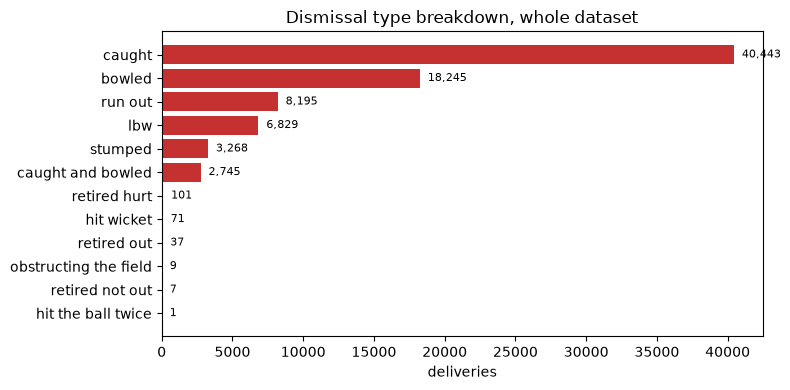

In [15]:
wicket_counts = q('''
    SELECT wicket_type, COUNT(*) AS n FROM deliveries
    WHERE wicket_type IS NOT NULL GROUP BY wicket_type ORDER BY n DESC
''')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(wicket_counts["wicket_type"], wicket_counts["n"], color="#c53030")
ax.invert_yaxis()
ax.set_xlabel("deliveries")
ax.set_title("Dismissal type breakdown, whole dataset")
for i, v in enumerate(wicket_counts["n"]):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
gt_breakdown = q('''
    SELECT gender, team_type, COUNT(*) AS matches FROM matches
    GROUP BY gender, team_type ORDER BY gender, team_type
''')
gt_breakdown

,gender,team_type,matches
0,female,club,969
1,female,international,2035
2,male,international,3393


Men's domestic data reads zero rows above -- consistent with §1: men's
domestic leagues (IPL/BBL/PSL/CPL) are configured in the ingestion pipeline
but not yet switched on, so every men's row today is `team_type='international'`.
Women's data is a genuine mix of international (2,035) and domestic/club
(969) matches, which is exactly the split `player_domestic_form` (see the
earlier conversation on domestic-form handling) depends on.

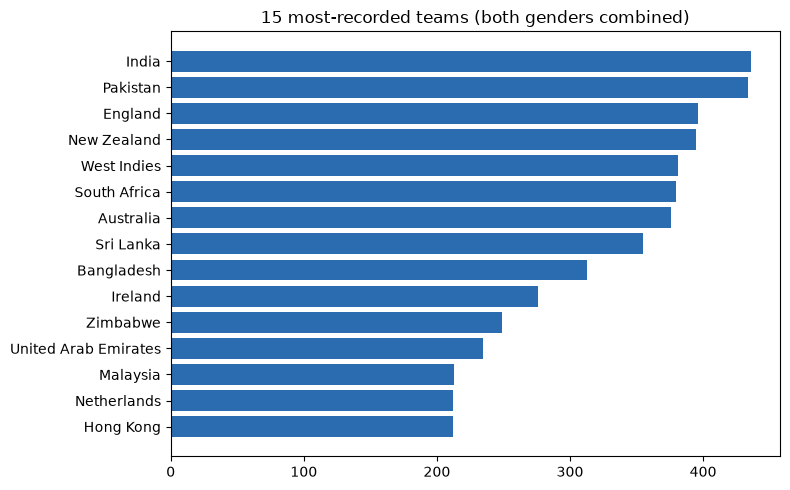

In [17]:
top_teams = q('''
    SELECT team, COUNT(*) AS matches FROM (
        SELECT team1 AS team FROM matches UNION ALL SELECT team2 AS team FROM matches
    ) GROUP BY team ORDER BY matches DESC LIMIT 15
''')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_teams["team"], top_teams["matches"], color="#2b6cb0")
ax.invert_yaxis()
ax.set_title("15 most-recorded teams (both genders combined)")
plt.tight_layout()
plt.show()

## 8. Arrangement over time — how the dataset has grown

Match volume by year, split by gender -- both to understand data
*density* (a model trained mostly on 2022-2026 data has much thinner
coverage of, say, 2010) and because this is a genuinely interesting real
pattern: T20 as a format, and its data coverage, both grew explosively in
the last ~6 years.

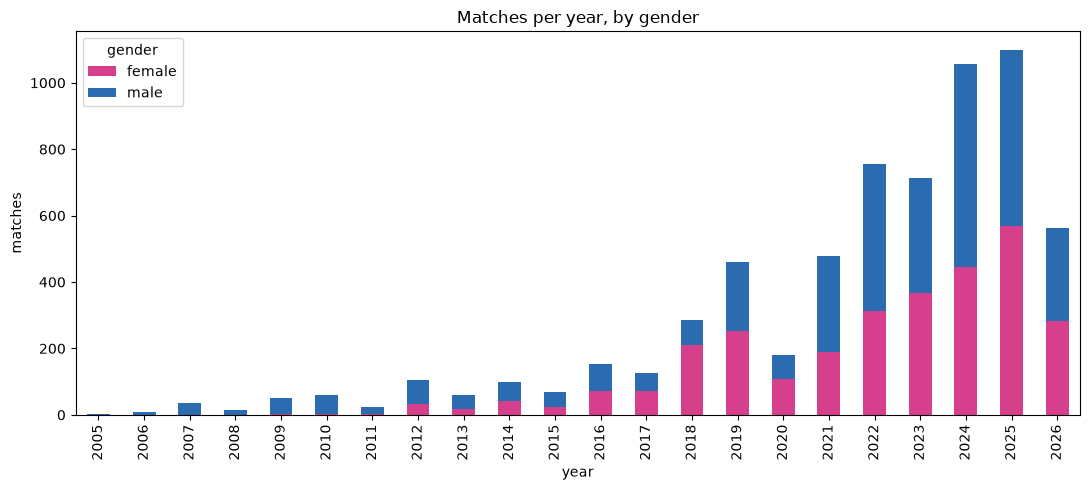

Date range: 2005-02-17 to 2026-06-15
Matches in the most recent full year on file vs the first 5 years combined:
gender  female   male
year                 
2026     282.0  282.0
gender
female      4.0
male      110.0
dtype: float64


In [18]:
by_year = q('''
    SELECT strftime('%Y', date) AS year, gender, COUNT(*) AS matches
    FROM matches GROUP BY year, gender ORDER BY year
''')
pivot = by_year.pivot(index="year", columns="gender", values="matches").fillna(0)

fig, ax = plt.subplots(figsize=(11, 5))
pivot.plot(kind="bar", stacked=True, ax=ax, color=["#d53f8c", "#2b6cb0"])
ax.set_title("Matches per year, by gender")
ax.set_ylabel("matches")
ax.set_xlabel("year")
plt.tight_layout()
plt.show()

print(f"Date range: {q('SELECT MIN(date) AS lo FROM matches')['lo'].iloc[0]} "
      f"to {q('SELECT MAX(date) AS hi FROM matches')['hi'].iloc[0]}")
print(f"Matches in the most recent full year on file vs the first 5 years combined:")
print(pivot.tail(1))
print(pivot.head(5).sum())

## 9. Outlier detection

### 9a. Innings totals -- IQR method

The standard, distribution-shape-agnostic outlier rule: flag anything more
than 1.5x the interquartile range beyond Q1/Q3. Applied to team innings
totals (from §6b).

Q1=96  Q3=155  IQR=59  -> outlier bounds: [8, 244]
111 of 12813 innings (0.9%) fall outside that range


C:\Users\shres\AppData\Local\Temp\ipykernel_39172\168307768.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(innings_totals["total"], vert=True)


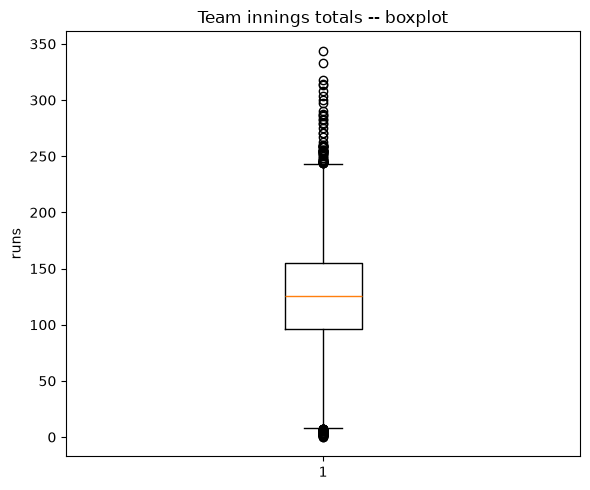

In [19]:
q1, q3 = innings_totals["total"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = innings_totals[(innings_totals["total"] < lo) | (innings_totals["total"] > hi)]
print(f"Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}  -> outlier bounds: [{lo:.0f}, {hi:.0f}]")
print(f"{len(outliers)} of {len(innings_totals)} innings ({100*len(outliers)/len(innings_totals):.1f}%) fall outside that range")

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(innings_totals["total"], vert=True)
ax.set_title("Team innings totals -- boxplot")
ax.set_ylabel("runs")
plt.tight_layout()
plt.show()

### 9b. Concrete extreme records

The outlier *rows themselves*, not just a count -- the highest team total,
the highest individual score, the best bowling figures, and single-ball
scoring anomalies, all read directly off the raw ball-by-ball data.

In [20]:
print("Top 5 highest team innings totals on record:")
display(innings_totals.sort_values("total", ascending=False).head(5))

print("\nTop 5 highest individual innings scores (runs off bat):")
top_scores = q('''
    SELECT match_id, innings, striker, SUM(runs_off_bat) AS runs
    FROM deliveries GROUP BY match_id, innings, striker ORDER BY runs DESC LIMIT 5
''')
display(top_scores)

print("\nTop 5 best single-innings bowling figures (wickets credited to the bowler):")
top_bowling = q('''
    SELECT match_id, innings, bowler, COUNT(*) AS wickets FROM deliveries
    WHERE player_dismissed IS NOT NULL
      AND wicket_type IN ('bowled','caught','lbw','stumped','caught and bowled','hit wicket')
    GROUP BY match_id, innings, bowler ORDER BY wickets DESC LIMIT 5
''')
display(top_bowling)

print("\nSingle-ball scoring anomalies -- runs_total should never legally exceed 7 "
      "(6 run-out-the-park + a rare extra run), so anything above that is worth a look:")
weird_balls = q("SELECT match_id, runs_off_bat, extras, runs_total FROM deliveries WHERE runs_total > 6 ORDER BY runs_total DESC LIMIT 10")
display(weird_balls)
print(f"({len(q('SELECT 1 AS x FROM deliveries WHERE runs_total > 6'))} deliveries total exceed 6 runs "
      f"out of {len(q('SELECT 1 AS x FROM deliveries'))} -- almost always a boundary plus overthrow(s), "
      f"a real (if rare) cricket event, not a data error.)")

Top 5 highest team innings totals on record:


,match_id,innings,total,wickets
7834,1453932,1,344,4
5883,1402766,1,333,1
3460,1306389,1,318,1
5773,1399104,1,314,3
11388,1538440,1,313,2



Top 5 highest individual innings scores (runs off bat):


,match_id,innings,striker,runs
0,1142915,1,AJ Finch,172
1,1535416,1,Hamza Khan,164
2,1306389,1,HMD Rasangika,161
3,1514476,1,Mohammad Ihsan,160
4,1306397,1,ER Oza,158



Top 5 best single-innings bowling figures (wickets credited to the bowler):


,match_id,innings,bowler,wickets
0,1528330,2,L Cardoso,9
1,1515012,2,S Yeshi,8
2,1274597,1,F Overdijk,7
3,1383101,1,Syazrul Idrus,7
4,1429013,2,R Rohmalia,7



Single-ball scoring anomalies -- runs_total should never legally exceed 7 (6 run-out-the-park + a rare extra run), so anything above that is worth a look:


,match_id,runs_off_bat,extras,runs_total
0,222678,6,2,8
1,1355587,6,2,8
2,1355600,6,2,8
3,1417855,6,2,8
4,1173058,6,1,7
5,1182649,6,1,7
6,1185156,6,1,7
7,1185156,6,1,7
8,1190606,6,1,7
9,1208808,6,1,7


(262 deliveries total exceed 6 runs out of 1443615 -- almost always a boundary plus overthrow(s), a real (if rare) cricket event, not a data error.)


### 9c. Career strike-rate / economy -- boxplots by gender

Same IQR logic, applied to the two headline performance metrics, split by
gender (a shared boxplot would blend two populations with different real
scoring eras/paces -- see §8).

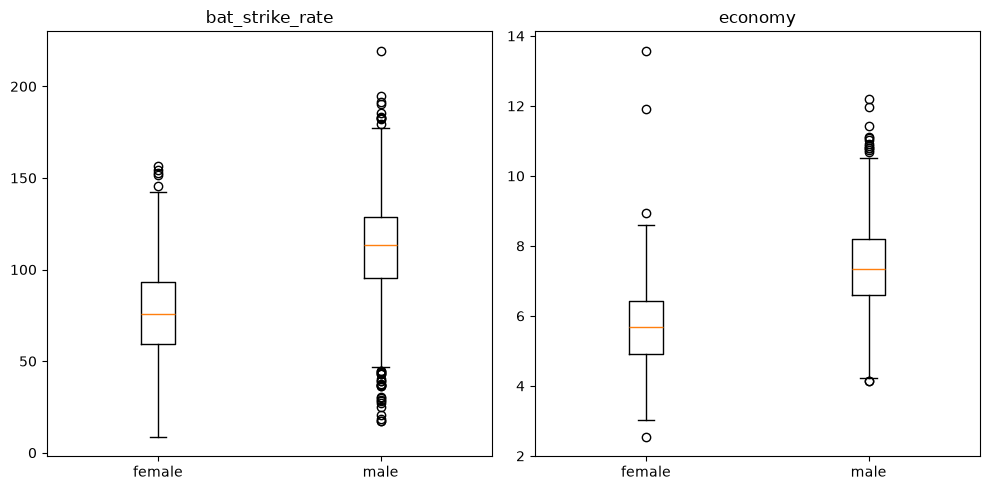

female: strike-rate IQR outlier bounds [8.1, 144.2] -- 5/872 players outside them
male: strike-rate IQR outlier bounds [46.0, 178.3] -- 34/1628 players outside them


In [21]:
career_g = q(f"SELECT player_id, bat_strike_rate, economy, bat_innings, bowl_innings FROM player_career WHERE format=?", (FMT,)).merge(player_gender, on="player_id", how="left")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, col, min_inns_col in zip(axes, ("bat_strike_rate", "economy"), ("bat_innings", "bowl_innings")):
    data = [career_g[(career_g["gender"] == g) & (career_g[min_inns_col] >= 10)][col].dropna() for g in ("female", "male")]
    ax.boxplot(data, tick_labels=["female", "male"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

for g in ("female", "male"):
    sub = career_g[(career_g["gender"] == g) & (career_g["bat_innings"] >= 10)]["bat_strike_rate"].dropna()
    q1, q3 = sub.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((sub < lo) | (sub > hi)).sum()
    print(f"{g}: strike-rate IQR outlier bounds [{lo:.1f}, {hi:.1f}] -- {n_out}/{len(sub)} players outside them")

## 10. Correlation heatmap -- do the performance metrics move together?

Joining `player_career` + `player_impact` per player/format, split by
gender, side by side.

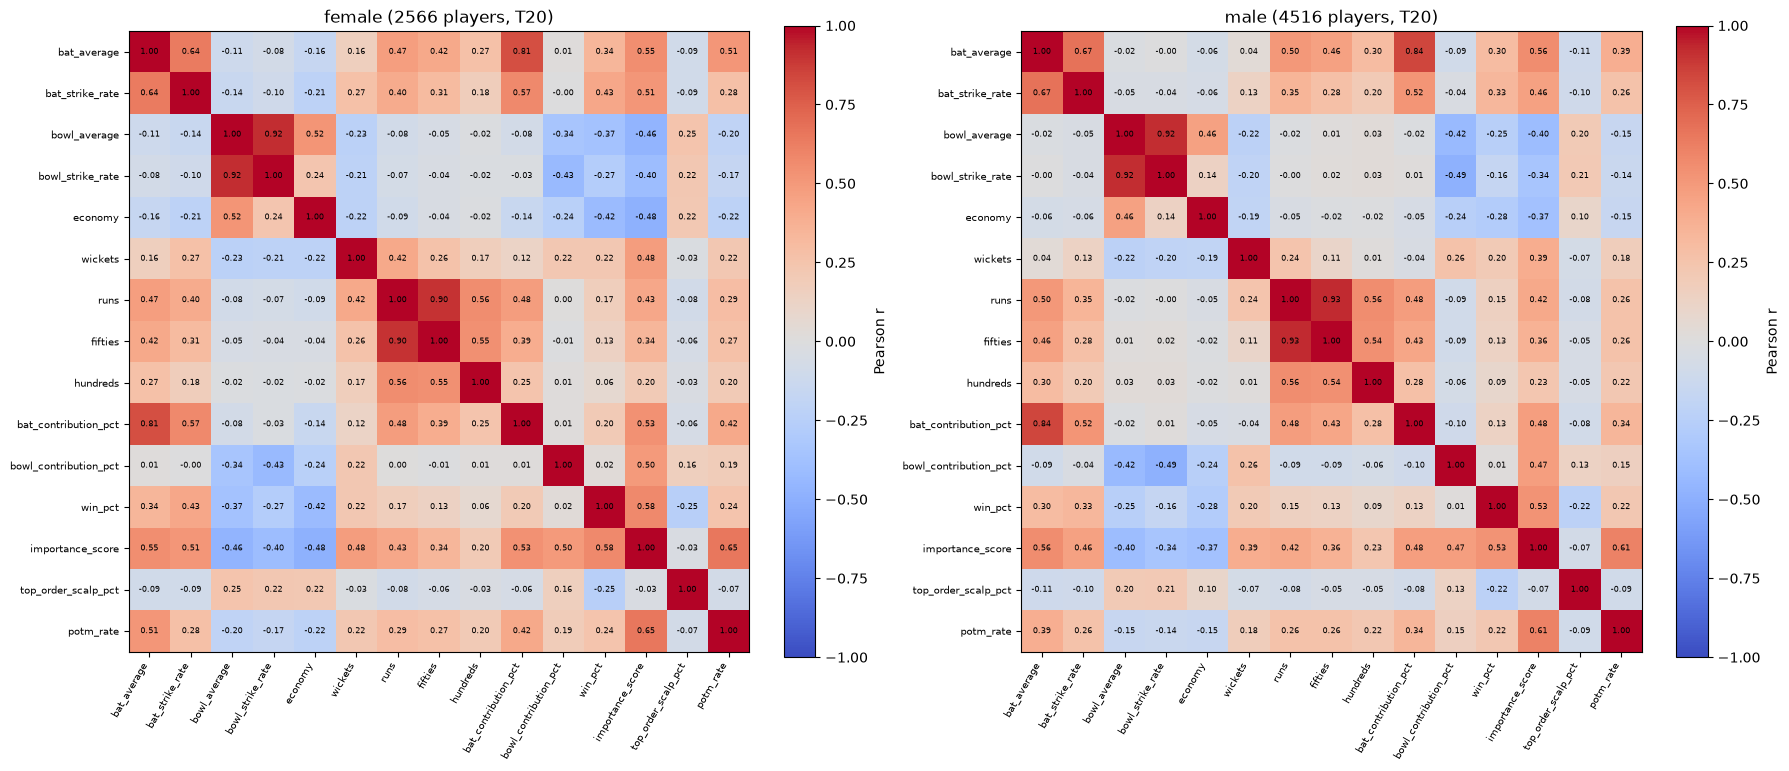

In [22]:
def perf_corr(gender):
    perf = q(f'''
        SELECT c.player_id, c.bat_average, c.bat_strike_rate, c.bowl_average, c.bowl_strike_rate,
               c.economy, c.wickets, c.runs, c.fifties, c.hundreds,
               i.bat_contribution_pct, i.bowl_contribution_pct, i.win_pct,
               i.importance_score, i.top_order_scalp_pct, i.potm_rate
        FROM player_career c JOIN player_impact i
          ON c.player_id = i.player_id AND c.format = i.format
        WHERE c.format = ?
    ''', (FMT,)).merge(player_gender, on="player_id", how="left")
    sub = perf[perf["gender"] == gender].drop(columns=["player_id", "gender"])
    return sub.corr(numeric_only=True), len(sub)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, gender in zip(axes, ("female", "male")):
    corr, n = perf_corr(gender)
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns, fontsize=7)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"{gender} ({n} players, {FMT})")
    fig.colorbar(im, ax=ax, label="Pearson r", fraction=0.046)
plt.tight_layout()
plt.show()

## 11. Batter-vs-bowler dismissal heatmap (female vs male, separately)

Top run-scorers vs top wicket-takers **within the same gender** -- they never
play each other in real cricket, so this must never mix pools. Uses
`dismissal_matchup` (6+ ball samples only).

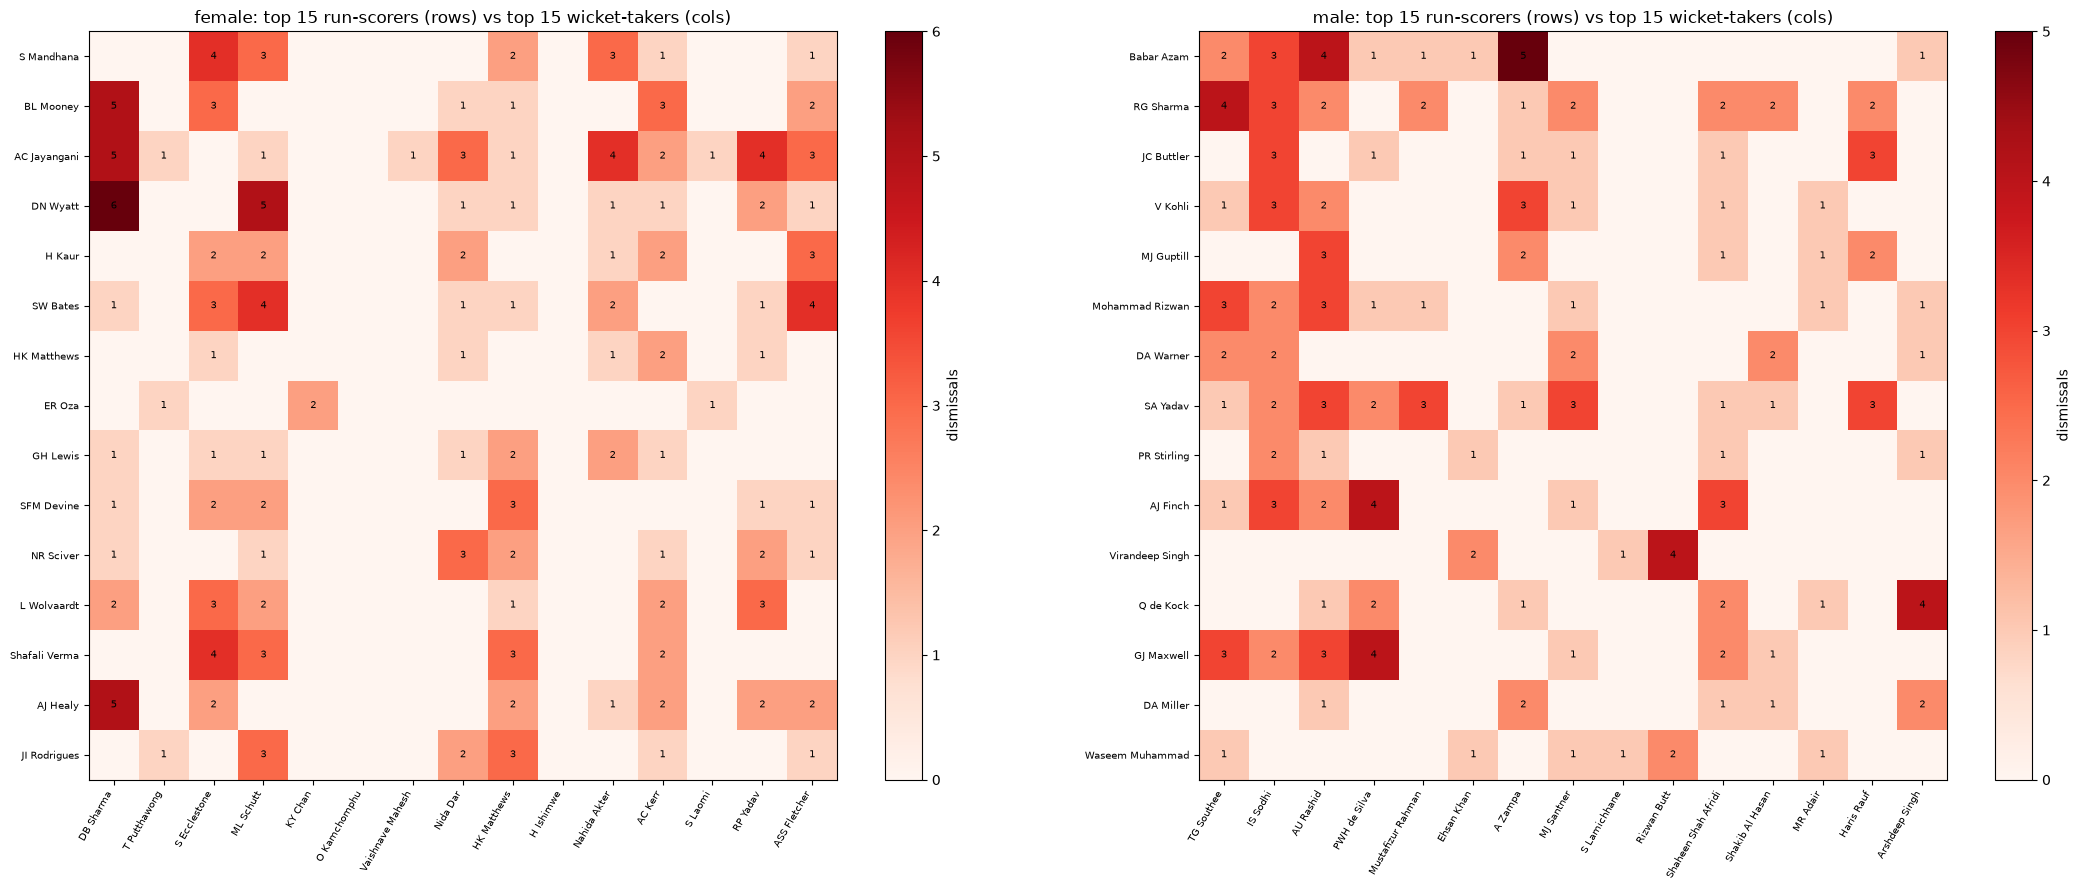

In [23]:
female_ids = set(player_gender.loc[player_gender.gender == "female", "player_id"])
male_ids = set(player_gender.loc[player_gender.gender == "male", "player_id"])

def top_players(ids, order_col, limit=15, extra_where=""):
    placeholders = ",".join("?" * len(ids))
    return q(f'''
        SELECT player_id, name FROM player_career
        WHERE format=? AND player_id IN ({placeholders}) {extra_where}
        ORDER BY {order_col} DESC LIMIT ?
    ''', (FMT, *ids, limit))

def dismissal_pivot(gender_ids):
    tb = top_players(gender_ids, "runs")
    tw = top_players(gender_ids, "wickets", extra_where="AND wickets > 0")
    bat_ids, bowl_ids = tuple(tb["player_id"]), tuple(tw["player_id"])
    ph_b = ",".join("?" * len(bat_ids)); ph_w = ",".join("?" * len(bowl_ids))
    dm = q(f'''
        SELECT batter_name, bowler_name, dismissals FROM dismissal_matchup
        WHERE format=? AND batter_id IN ({ph_b}) AND bowler_id IN ({ph_w})
    ''', (FMT, *bat_ids, *bowl_ids))
    pivot = dm.pivot_table(index="batter_name", columns="bowler_name", values="dismissals",
                            aggfunc="sum", fill_value=0)
    return pivot.reindex(index=tb["name"], columns=tw["name"], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, gender, ids in zip(axes, ("female", "male"), (female_ids, male_ids)):
    pivot = dismissal_pivot(ids)
    im = ax.imshow(pivot.values, cmap="Reds")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=7)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if v > 0:
                ax.text(j, i, int(v), ha="center", va="center", fontsize=7)
    ax.set_title(f"{gender}: top 15 run-scorers (rows) vs top 15 wicket-takers (cols)")
    fig.colorbar(im, ax=ax, label="dismissals", fraction=0.046)
plt.tight_layout()
plt.show()

## 12. Phase performance heatmap (powerplay / middle / death)

Batting strike rate by phase, for each gender's own top run-scorers.

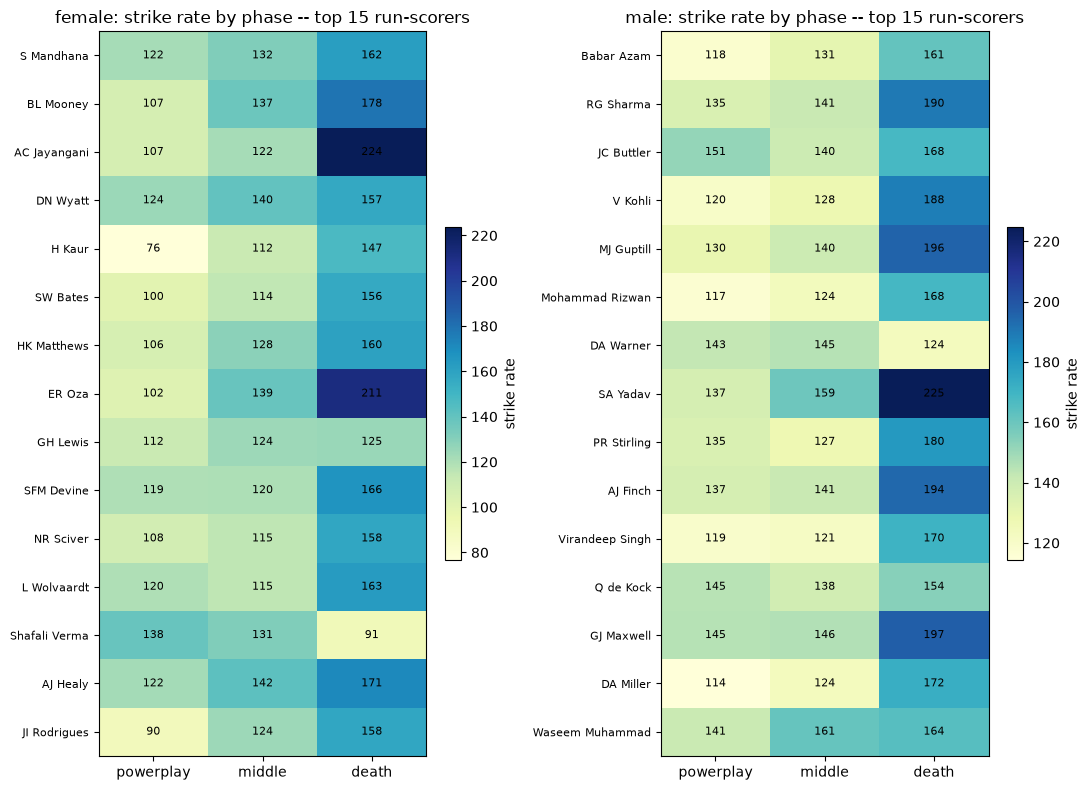

In [24]:
def phase_pivot(gender_ids):
    tb = top_players(gender_ids, "runs")
    ph_ids = ",".join("?" * len(tb))
    ph = q(f'''
        SELECT p.name, ph.phase, ph.bat_strike_rate
        FROM player_phase ph JOIN player_career p
          ON ph.player_id = p.player_id AND ph.format = p.format
        WHERE ph.format=? AND ph.player_id IN ({ph_ids})
    ''', (FMT, *tb["player_id"]))
    phase_order = ["powerplay", "middle", "death"]
    pivot = ph.pivot_table(index="name", columns="phase", values="bat_strike_rate")
    return pivot.reindex(index=tb["name"], columns=[c for c in phase_order if c in pivot.columns])

fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for ax, gender, ids in zip(axes, ("female", "male"), (female_ids, male_ids)):
    pivot = phase_pivot(ids)
    im = ax.imshow(pivot.values, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=8)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{gender}: strike rate by phase -- top 15 run-scorers")
    fig.colorbar(im, ax=ax, label="strike rate", fraction=0.046)
plt.tight_layout()
plt.show()

## 13. Team-vs-team win-rate heatmap

From `matches` directly (result-level) -- `gender` is a real stored column
here already.

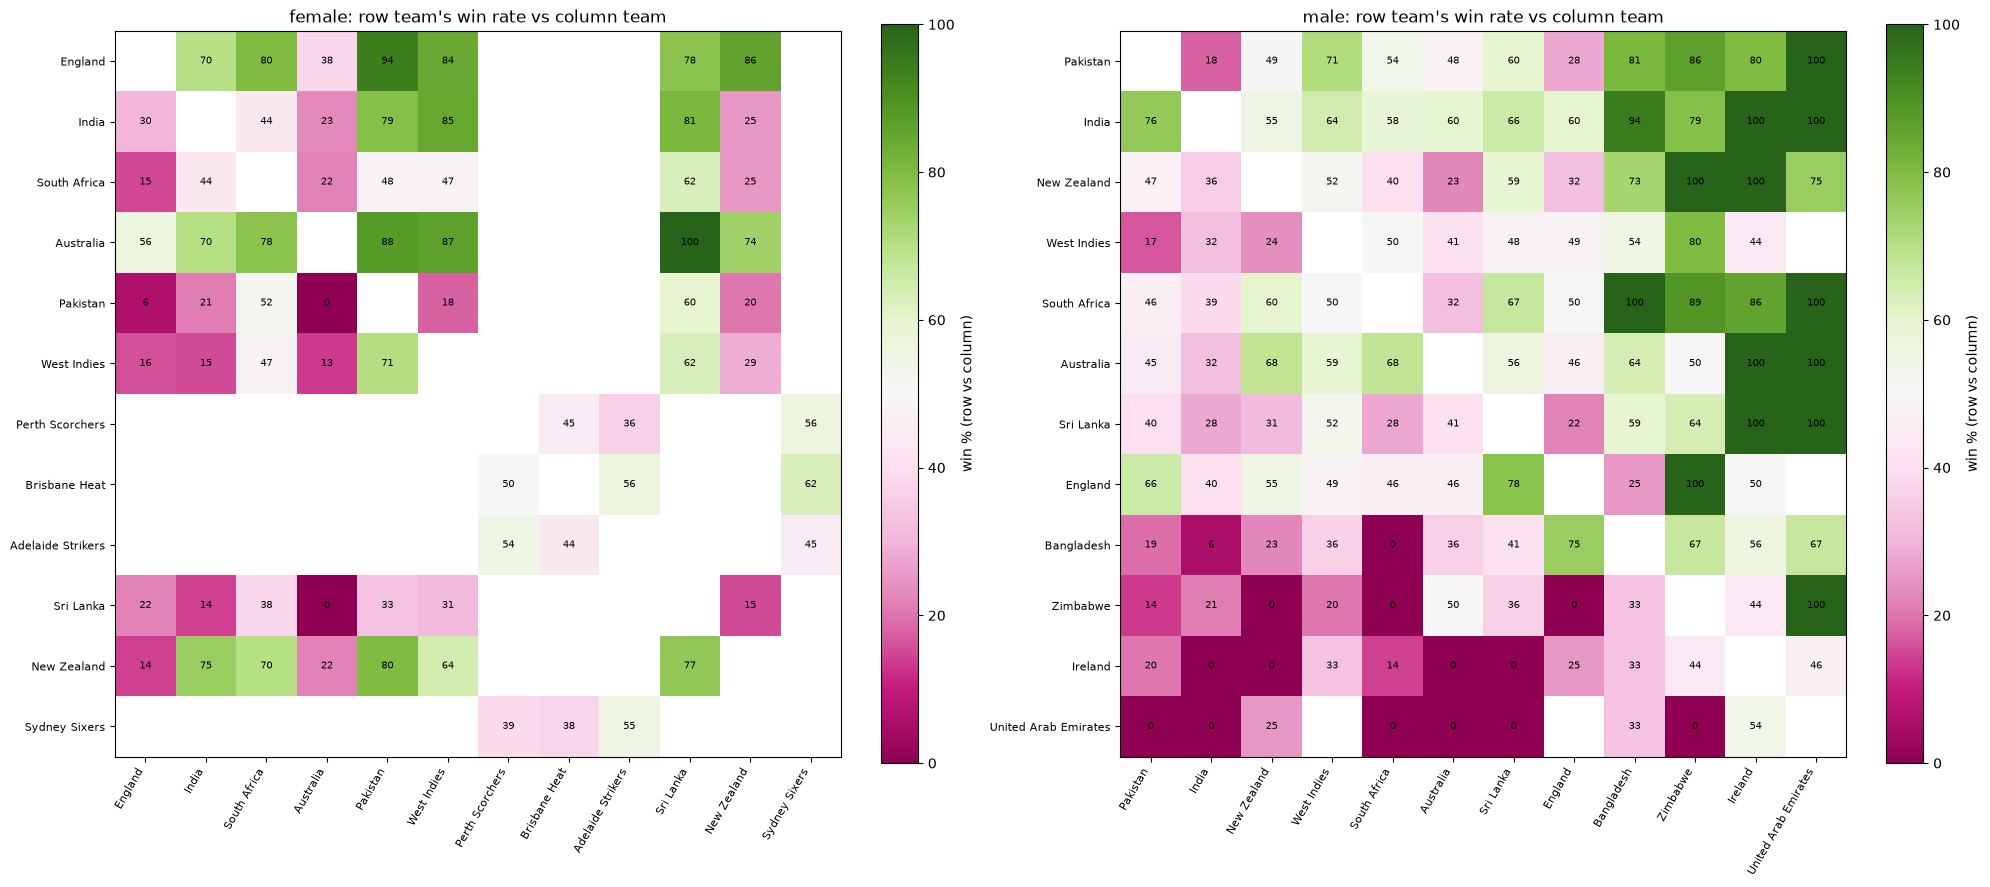

In [25]:
def win_rate_matrix(gender):
    top_teams = q(f'''
        SELECT team FROM (
            SELECT team1 AS team FROM matches WHERE format=? AND gender=?
            UNION ALL
            SELECT team2 AS team FROM matches WHERE format=? AND gender=?
        ) GROUP BY team ORDER BY COUNT(*) DESC LIMIT 12
    ''', (FMT, gender, FMT, gender))["team"].tolist()

    ph_t = ",".join("?" * len(top_teams))
    mm = q(f'''
        SELECT team1, team2, winner FROM matches
        WHERE format=? AND gender=? AND team1 IN ({ph_t}) AND team2 IN ({ph_t})
    ''', (FMT, gender, *top_teams, *top_teams))

    win_rate = pd.DataFrame(index=top_teams, columns=top_teams, dtype=float)
    for a in top_teams:
        for b in top_teams:
            if a == b:
                continue
            played = mm[((mm.team1 == a) & (mm.team2 == b)) | ((mm.team1 == b) & (mm.team2 == a))]
            if len(played) == 0:
                continue
            wins = (played["winner"] == a).sum()
            win_rate.loc[a, b] = round(100 * wins / len(played), 1)
    return win_rate

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, gender in zip(axes, ("female", "male")):
    win_rate = win_rate_matrix(gender)
    im = ax.imshow(win_rate.values.astype(float), cmap="PiYG", vmin=0, vmax=100)
    ax.set_xticks(range(len(win_rate.columns))); ax.set_xticklabels(win_rate.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(win_rate.columns))); ax.set_yticklabels(win_rate.columns, fontsize=8)
    for i in range(win_rate.shape[0]):
        for j in range(win_rate.shape[1]):
            v = win_rate.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{gender}: row team's win rate vs column team")
    fig.colorbar(im, ax=ax, label="win % (row vs column)", fraction=0.046)
plt.tight_layout()
plt.show()

## 14. Distributions -- strike rate & economy, female vs male

Histograms split by gender rather than overlaid unlabeled, since the two
pools have different match volumes and eras (women's T20I data starts later
and has fewer matches per player on average -- see §8).

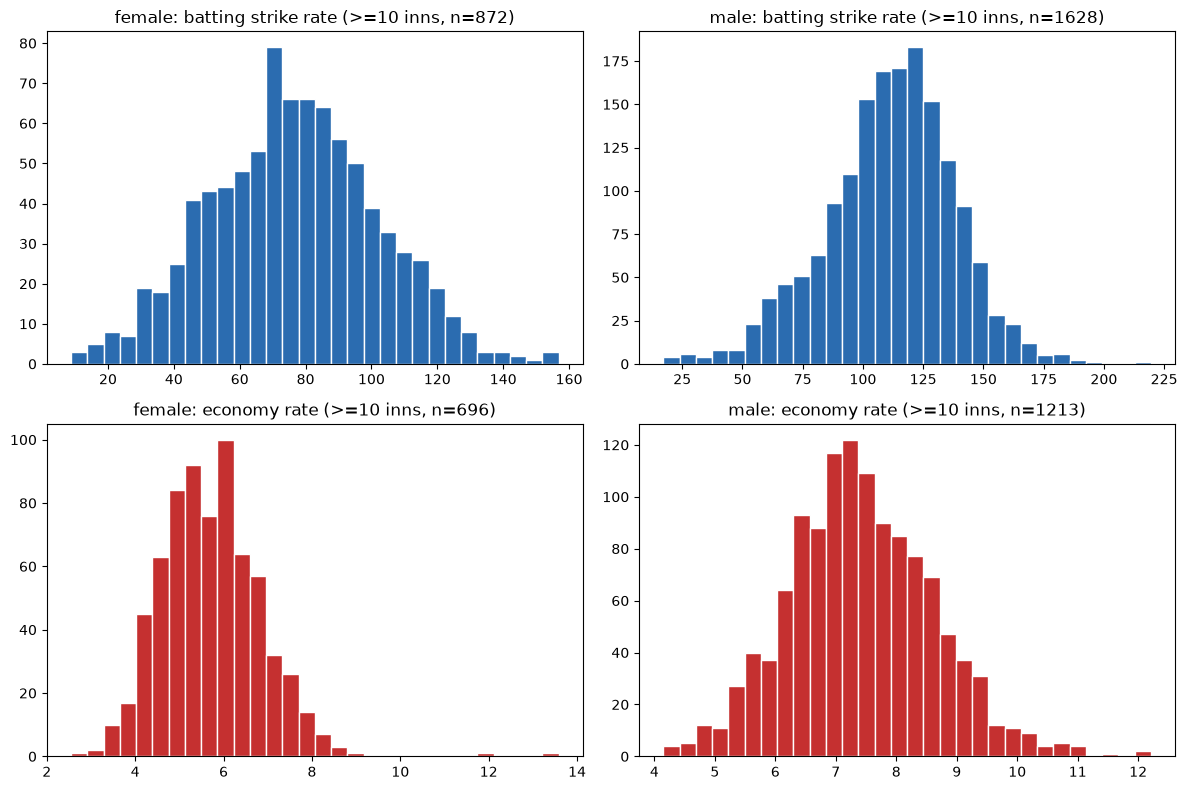

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col_ax, gender in zip(axes.T, ("female", "male")):
    sub = career_g[career_g["gender"] == gender]
    sr = sub[sub["bat_innings"] >= 10]["bat_strike_rate"].dropna()
    eco = sub[sub["bowl_innings"] >= 10]["economy"].dropna()
    col_ax[0].hist(sr, bins=30, color="#2b6cb0", edgecolor="white")
    col_ax[0].set_title(f"{gender}: batting strike rate (>=10 inns, n={len(sr)})")
    col_ax[1].hist(eco, bins=30, color="#c53030", edgecolor="white")
    col_ax[1].set_title(f"{gender}: economy rate (>=10 inns, n={len(eco)})")

plt.tight_layout()
plt.show()

## 15. Summary -- what this dataset supports, and what it doesn't

**Recap of the dataset's real shape:**

In [27]:
summary_facts = {
    "Total matches": q("SELECT COUNT(*) AS n FROM matches")["n"].iloc[0],
    "Total deliveries (balls)": q("SELECT COUNT(*) AS n FROM deliveries")["n"].iloc[0],
    "Date range": f"{q('SELECT MIN(date) AS lo FROM matches')['lo'].iloc[0]} to {q('SELECT MAX(date) AS hi FROM matches')['hi'].iloc[0]}",
    "Distinct teams": q("SELECT COUNT(DISTINCT team) AS n FROM (SELECT team1 AS team FROM matches UNION SELECT team2 FROM matches)")["n"].iloc[0],
    "Distinct venues (canonicalized)": q("SELECT COUNT(DISTINCT venue_id) AS n FROM matches")["n"].iloc[0],
    "Distinct players (career table)": q("SELECT COUNT(*) AS n FROM player_career WHERE format=?", (FMT,))["n"].iloc[0],
    "Database file size (MB)": round(os.path.getsize(DB_PATH) / 1e6, 1),
    "Total tables": len(tables),
}
for k, v in summary_facts.items():
    print(f"{k}: {v:,}" if isinstance(v, (int, float)) else f"{k}: {v}")

Total matches: 6397
Total deliveries (balls): 1443615
Date range: 2005-02-17 to 2026-06-15
Distinct teams: 153
Distinct venues (canonicalized): 370
Distinct players (career table): 7085
Database file size (MB): 494.6
Total tables: 33


**What this dataset genuinely supports:** real ball-by-ball
reconstruction of any match on file (scorecards, win-probability replay,
phase splits), career/form/matchup/venue statistics at any point-in-time cut
(no leakage), and the correlation/distribution analysis above.

**What it doesn't support** (see the earlier conversation on this, and
`model-training/README.md`'s "Known Limitations"): the correlation heatmaps
above describe *association*, not *predictive power* -- `model_comparison.ipynb`
in `model-training/` is the notebook that actually measures held-out
predictive performance, and its honest result is that predicting single-
match WPA from pre-match features only slightly beats a mean-predictor
baseline. Shot-type/line-length data (which shot, where on the pitch) isn't
in Cricsheet at all and isn't faked here. Men's domestic-league data doesn't
exist yet (§7) -- `domestic_form_*` features are currently a women's-only
signal.

`conn.close()` below releases the SQLite handle.

In [28]:
conn.close()